In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Our project has started!")

Our project has started!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving city_day.csv to city_day.csv


In [ ]:
df = pd.read_csv("city_day.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [ ]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Total rows: 29531
Total columns: 16


In [ ]:
df.isnull().sum()

,0
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


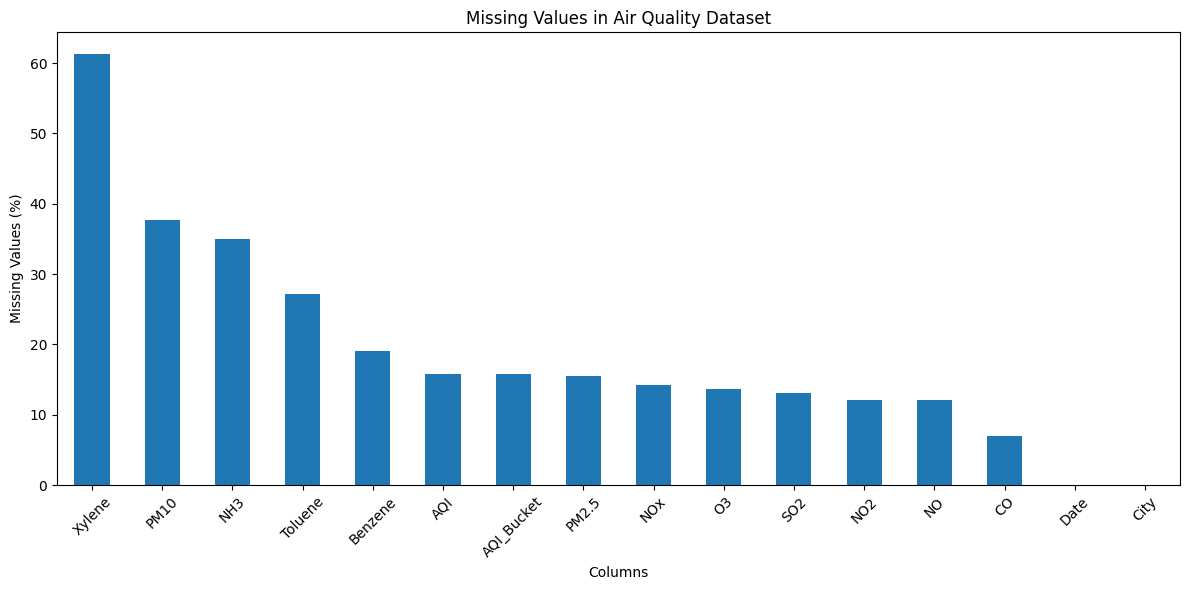

In [ ]:
# Calculate missing values as percentages
missing_percent = (df.isnull().sum() / len(df)) * 100

# Sort from highest to lowest
missing_percent = missing_percent.sort_values(ascending=False)

# Plot the results
plt.figure(figsize=(12, 6))
missing_percent.plot(kind="bar")

plt.title("Missing Values in Air Quality Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
# Convert Date to datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Display the date range
print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

# Count unique cities
print("Number of cities:", df["City"].nunique())

# List all cities
print("\nCities in dataset:")
print(sorted(df["City"].dropna().unique()))

Earliest date: 2015-01-01 00:00:00
Latest date: 2020-07-01 00:00:00
Number of cities: 26

Cities in dataset:
['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']


In [ ]:
total_rows = len(df)
available_aqi = df["AQI"].notna().sum()
missing_aqi = df["AQI"].isna().sum()

print("Total records:", total_rows)
print("Available AQI records:", available_aqi)
print("Missing AQI records:", missing_aqi)
print("AQI availability:", round(available_aqi / total_rows * 100, 2), "%")

Total records: 29531
Available AQI records: 24850
Missing AQI records: 4681
AQI availability: 84.15 %


In [ ]:
# Check data types
print(df.dtypes)

City                  object
Date          datetime64[ns]
PM2.5                float64
PM10                 float64
NO                   float64
NO2                  float64
NOx                  float64
NH3                  float64
CO                   float64
SO2                  float64
O3                   float64
Benzene              float64
Toluene              float64
Xylene               float64
AQI                  float64
AQI_Bucket            object
dtype: object


In [ ]:
# Keep the original dataset unchanged
df_clean = df.copy()

print("Working copy created!")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

Working copy created!
Rows: 29531
Columns: 16


In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary

,Missing Count,Missing Percentage
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
AQI,4681,15.85
AQI_Bucket,4681,15.85
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62


In [ ]:
# Keep records where AQI is available
df_aqi = df_clean.dropna(subset=["AQI"]).copy()

print("Original records:", len(df_clean))
print("Records with AQI:", len(df_aqi))
print("Records removed:", len(df_clean) - len(df_aqi))
print("Remaining missing AQI:", df_aqi["AQI"].isnull().sum())

Original records: 29531
Records with AQI: 24850
Records removed: 4681
Remaining missing AQI: 0


In [ ]:
print(df_aqi["AQI"].describe())

count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64


In [ ]:
print("AQI values <= 0:", (df_aqi["AQI"] <= 0).sum())
print("AQI values < 0:", (df_aqi["AQI"] < 0).sum())

AQI values <= 0: 0
AQI values < 0: 0


In [ ]:
city_aqi = (
    df_aqi.groupby("City")["AQI"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

city_aqi.head(10)

,count,mean,median
City,,,
Ahmedabad,1334,452.12,384.5
Delhi,1999,259.49,257.0
Patna,1459,240.78,215.0
Gurugram,1453,225.12,208.0
Lucknow,1893,217.97,198.0
Talcher,698,172.89,128.5
Jorapokhar,771,159.25,133.0
Brajrajnagar,713,150.28,122.0
Kolkata,754,140.57,94.0


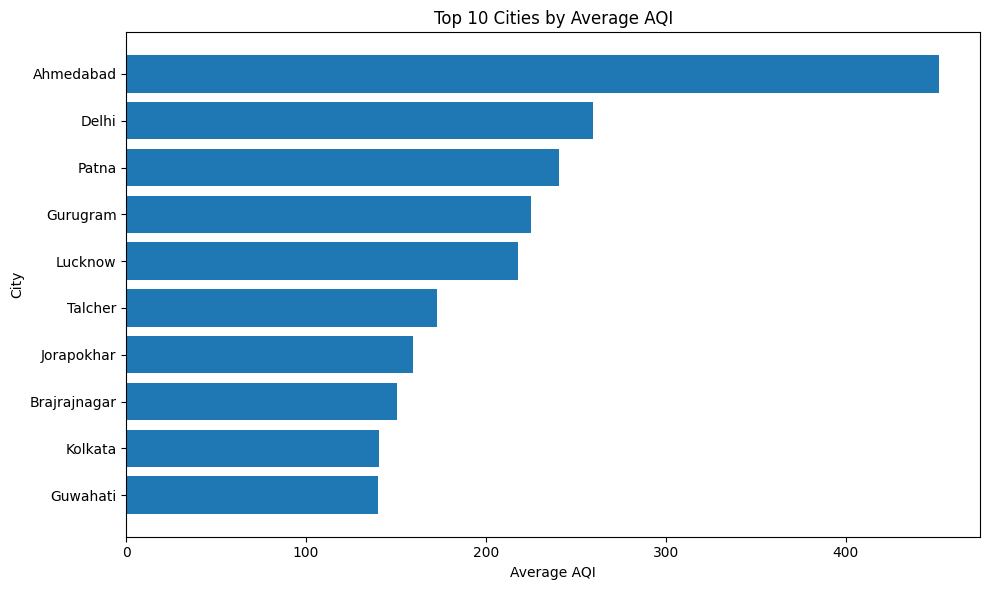

In [ ]:
top_10 = city_aqi.head(10).sort_values("mean")

plt.figure(figsize=(10, 6))

plt.barh(top_10.index, top_10["mean"])

plt.title("Top 10 Cities by Average AQI")
plt.xlabel("Average AQI")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [5]:
from google.colab import files

uploaded = files.upload()

Saving city_day.csv to city_day.csv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("city_day.csv")

print("Dataset loaded:", df.shape)

Dataset loaded: (29531, 16)


In [7]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df_aqi = df.dropna(subset=["AQI"]).copy()

print("AQI records:", len(df_aqi))

AQI records: 24850


In [8]:
highest_aqi = df_aqi.nlargest(10, "AQI")[
    ["City", "Date", "AQI", "AQI_Bucket"]
]

highest_aqi

,City,Date,AQI,AQI_Bucket
1145,Ahmedabad,2018-02-19,2049.0,Severe
1136,Ahmedabad,2018-02-10,1917.0,Severe
560,Ahmedabad,2016-07-14,1842.0,Severe
1048,Ahmedabad,2017-11-14,1747.0,Severe
1463,Ahmedabad,2019-01-03,1719.0,Severe
1417,Ahmedabad,2018-11-18,1672.0,Severe
1420,Ahmedabad,2018-11-21,1646.0,Severe
1407,Ahmedabad,2018-11-08,1630.0,Severe
1127,Ahmedabad,2018-02-01,1613.0,Severe
1746,Ahmedabad,2019-10-13,1595.0,Severe


In [9]:
highest_aqi = df_aqi.nlargest(10, "AQI")[
    ["City", "Date", "AQI", "AQI_Bucket"]
]

highest_aqi

,City,Date,AQI,AQI_Bucket
1145,Ahmedabad,2018-02-19,2049.0,Severe
1136,Ahmedabad,2018-02-10,1917.0,Severe
560,Ahmedabad,2016-07-14,1842.0,Severe
1048,Ahmedabad,2017-11-14,1747.0,Severe
1463,Ahmedabad,2019-01-03,1719.0,Severe
1417,Ahmedabad,2018-11-18,1672.0,Severe
1420,Ahmedabad,2018-11-21,1646.0,Severe
1407,Ahmedabad,2018-11-08,1630.0,Severe
1127,Ahmedabad,2018-02-01,1613.0,Severe
1746,Ahmedabad,2019-10-13,1595.0,Severe


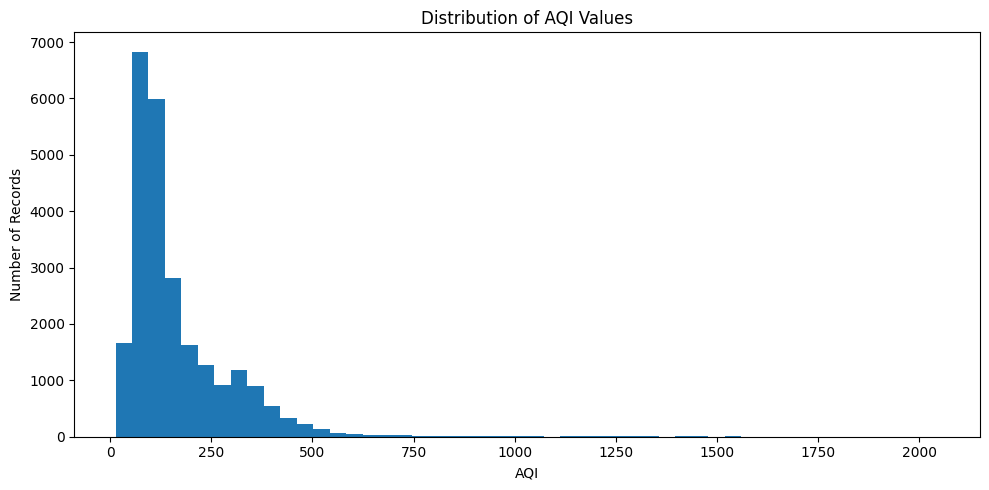

In [10]:
plt.figure(figsize=(10, 5))

plt.hist(df_aqi["AQI"], bins=50)

plt.title("Distribution of AQI Values")
plt.xlabel("AQI")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [11]:
print("AQI above 500:", (df_aqi["AQI"] > 500).sum())

print("\nRecords above 500:")
df_aqi.loc[
    df_aqi["AQI"] > 500,
    ["City", "Date", "AQI", "AQI_Bucket"]
].sort_values("AQI", ascending=False).head(15)

AQI above 500: 543

Records above 500:


,City,Date,AQI,AQI_Bucket
1145,Ahmedabad,2018-02-19,2049.0,Severe
1136,Ahmedabad,2018-02-10,1917.0,Severe
560,Ahmedabad,2016-07-14,1842.0,Severe
1048,Ahmedabad,2017-11-14,1747.0,Severe
1463,Ahmedabad,2019-01-03,1719.0,Severe
1417,Ahmedabad,2018-11-18,1672.0,Severe
1420,Ahmedabad,2018-11-21,1646.0,Severe
1407,Ahmedabad,2018-11-08,1630.0,Severe
1127,Ahmedabad,2018-02-01,1613.0,Severe
1746,Ahmedabad,2019-10-13,1595.0,Severe


In [12]:
city_aqi = (
    df_aqi.groupby("City")["AQI"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

city_aqi

,count,mean,median
City,,,
Ahmedabad,1334,452.12,384.5
Delhi,1999,259.49,257.0
Patna,1459,240.78,215.0
Gurugram,1453,225.12,208.0
Lucknow,1893,217.97,198.0
Talcher,698,172.89,128.5
Jorapokhar,771,159.25,133.0
Brajrajnagar,713,150.28,122.0
Kolkata,754,140.57,94.0


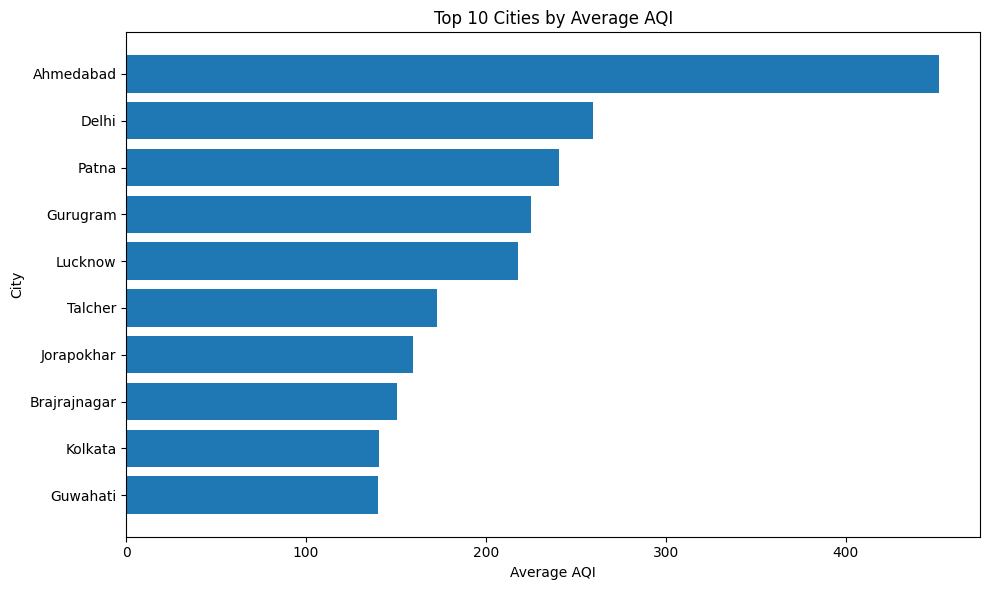

In [13]:
top_10 = city_aqi.head(10).sort_values("mean")

plt.figure(figsize=(10, 6))

plt.barh(top_10.index, top_10["mean"])

plt.title("Top 10 Cities by Average AQI")
plt.xlabel("Average AQI")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [14]:
df_aqi["Year"] = df_aqi["Date"].dt.year
df_aqi["Month"] = df_aqi["Date"].dt.month

print(df_aqi[["Date", "Year", "Month"]].head())

         Date  Year  Month
28 2015-01-29  2015      1
29 2015-01-30  2015      1
30 2015-01-31  2015      1
31 2015-02-01  2015      2
32 2015-02-02  2015      2


In [15]:
monthly_aqi = (
    df_aqi.groupby("Month")["AQI"]
    .mean()
    .round(2)
)

monthly_aqi

,AQI
Month,
1,231.67
2,202.91
3,164.74
4,143.36
5,135.49
6,120.20
7,111.85
8,113.61
9,115.19


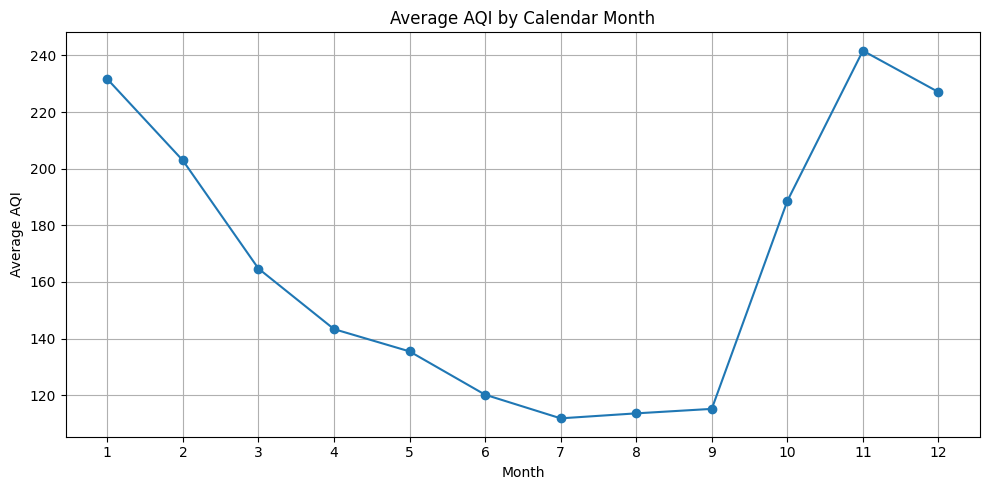

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_aqi.index,
    monthly_aqi.values,
    marker="o"
)

plt.title("Average AQI by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")

plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

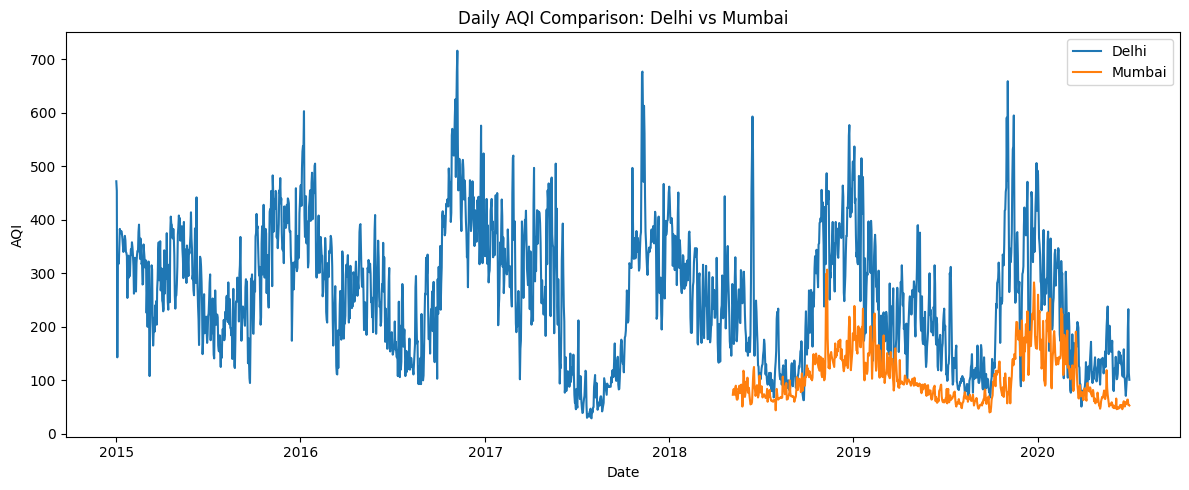

In [17]:
selected_cities = df_aqi[
    df_aqi["City"].isin(["Delhi", "Mumbai"])
]

city_monthly = (
    selected_cities
    .groupby(["Date", "City"])["AQI"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

for city in ["Delhi", "Mumbai"]:
    city_data = city_monthly[city_monthly["City"] == city]

    plt.plot(
        city_data["Date"],
        city_data["AQI"],
        label=city
    )

plt.title("Daily AQI Comparison: Delhi vs Mumbai")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.tight_layout()
plt.show()

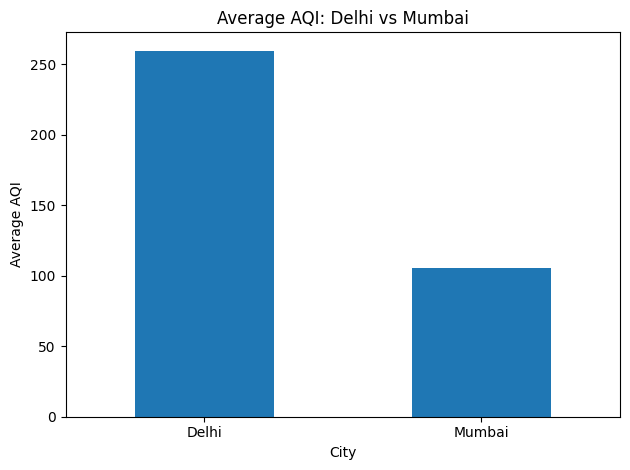

In [21]:
city_aqi = (
    df_aqi[df_aqi["City"].isin(["Delhi", "Mumbai"])]
    .groupby("City")["AQI"]
    .mean()
)

city_aqi.plot(kind="bar")

plt.title("Average AQI: Delhi vs Mumbai")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

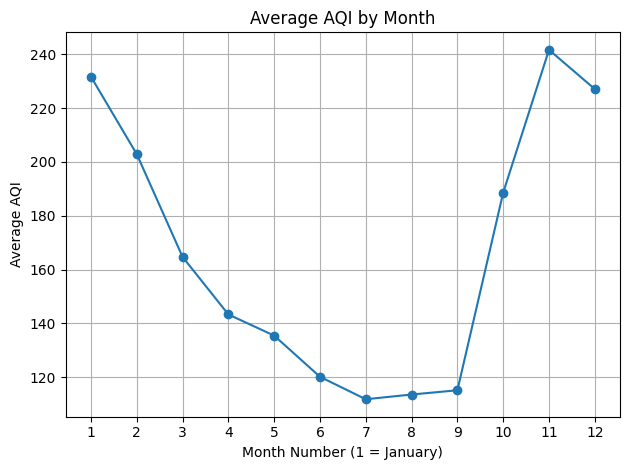

In [22]:
monthly_aqi = df_aqi.groupby(
    df_aqi["Date"].dt.month
)["AQI"].mean()

monthly_aqi.plot(kind="line", marker="o")

plt.title("Average AQI by Month")
plt.xlabel("Month Number (1 = January)")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
city_ranking = (
    df_aqi.groupby("City")["AQI"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(city_ranking.to_string())

City
Ahmedabad             452.12
Delhi                 259.49
Patna                 240.78
Gurugram              225.12
Lucknow               217.97
Talcher               172.89
Jorapokhar            159.25
Brajrajnagar          150.28
Kolkata               140.57
Guwahati              140.11
Jaipur                133.68
Bhopal                132.83
Amritsar              119.92
Visakhapatnam         117.27
Chennai               114.50
Hyderabad             109.21
Mumbai                105.35
Kochi                 104.28
Chandigarh             96.50
Amaravati              95.30
Bengaluru              94.32
Ernakulam              92.36
Thiruvananthapuram     75.88
Coimbatore             73.02
Shillong               53.80
Aizawl                 34.77


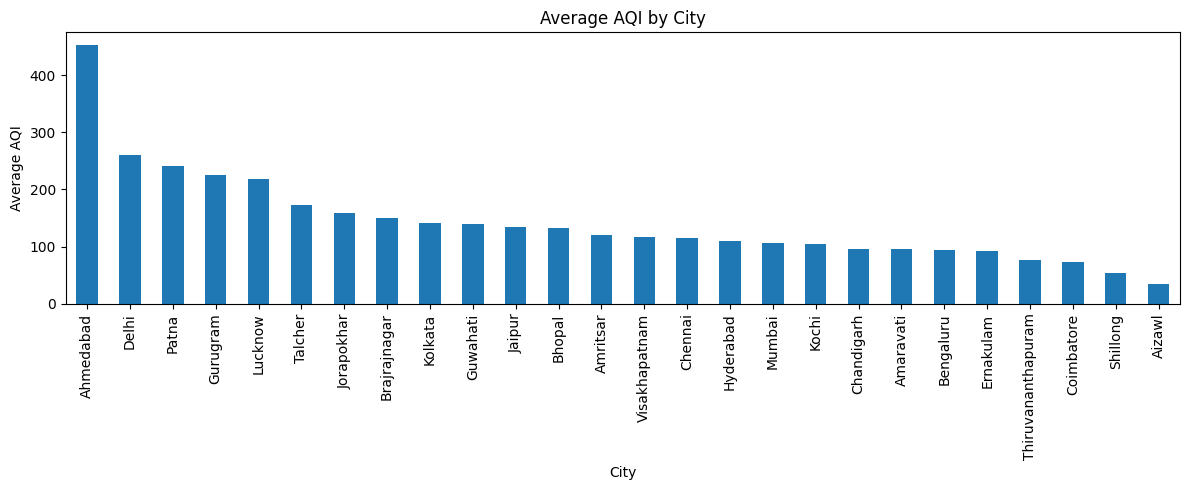

In [24]:
city_ranking.plot(kind="bar", figsize=(12, 5))

plt.title("Average AQI by City")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [25]:
print("Top 5 cities by average AQI:")
print(city_ranking.head(5))

Top 5 cities by average AQI:
City
Ahmedabad    452.12
Delhi        259.49
Patna        240.78
Gurugram     225.12
Lucknow      217.97
Name: AQI, dtype: float64


In [26]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0].sort_values(ascending=False))

Missing values in each column:
Xylene        18109
PM10          11140
NH3           10328
Toluene        8041
Benzene        5623
AQI            4681
AQI_Bucket     4681
PM2.5          4598
NOx            4185
O3             4022
SO2            3854
NO2            3585
NO             3582
CO             2059
dtype: int64


In [27]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

print("Missing values percentage:")
print(missing_percentage[missing_percentage > 0].sort_values(ascending=False))

Missing values percentage:
Xylene        61.32
PM10          37.72
NH3           34.97
Toluene       27.23
Benzene       19.04
AQI           15.85
AQI_Bucket    15.85
PM2.5         15.57
NOx           14.17
O3            13.62
SO2           13.05
NO2           12.14
NO            12.13
CO             6.97
dtype: float64


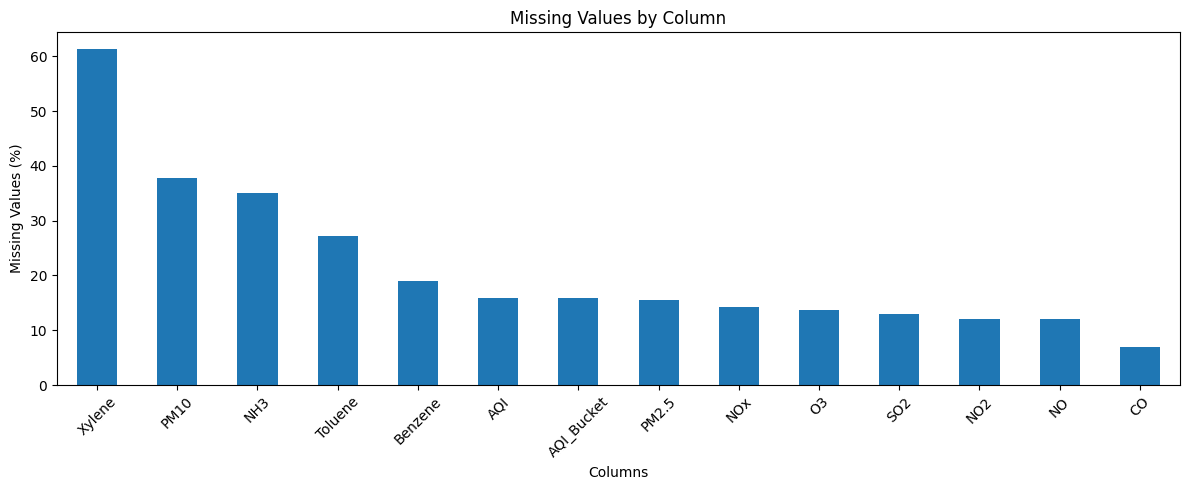

In [28]:
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percentage = missing_percentage[
    missing_percentage > 0
]

missing_percentage.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
df_clean = df.dropna(subset=["AQI"]).copy()

print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)

print(
    "Missing AQI after cleaning:",
    df_clean["AQI"].isnull().sum()
)

Original dataset shape: (29531, 16)
Clean dataset shape: (24850, 16)
Missing AQI after cleaning: 0


In [30]:
# Count AQI categories
print(df_clean["AQI_Bucket"].value_counts())

AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64


In [31]:
category_percentage = (
    df_clean["AQI_Bucket"]
    .value_counts(normalize=True) * 100
).round(2)

print("\nAQI Category Percentage:")
print(category_percentage)


AQI Category Percentage:
AQI_Bucket
Moderate        35.53
Satisfactory    33.09
Poor            11.19
Very Poor        9.40
Good             5.40
Severe           5.38
Name: proportion, dtype: float64


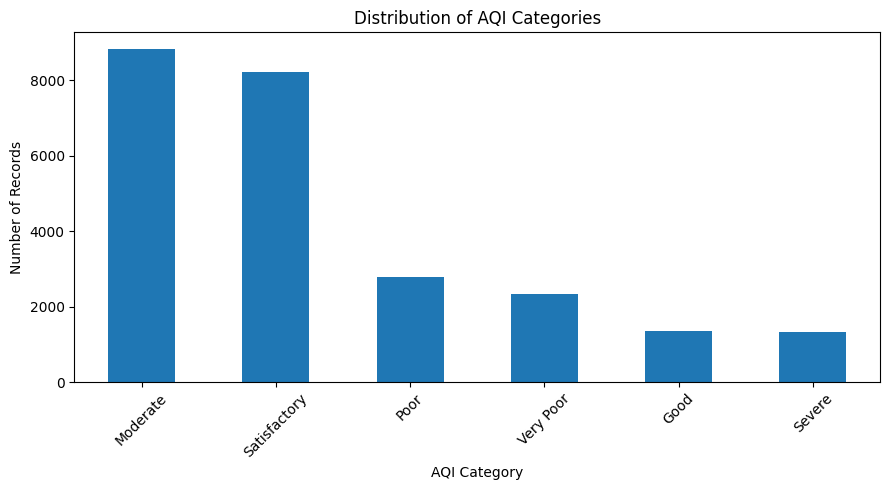

In [32]:
df_clean["AQI_Bucket"].value_counts().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribution of AQI Categories")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
# Correlation between pollutants and AQI

pollutants = [
    "PM2.5", "PM10", "NO", "NO2",
    "NOx", "NH3", "CO", "SO2", "O3"
]

correlation = (
    df_clean[pollutants + ["AQI"]]
    .corr(numeric_only=True)["AQI"]
    .drop("AQI")
    .sort_values(ascending=False)
)

print("Correlation of pollutants with AQI:")
print(correlation.round(3))

Correlation of pollutants with AQI:
PM10     0.803
CO       0.683
PM2.5    0.659
NO2      0.537
SO2      0.491
NOx      0.486
NO       0.452
NH3      0.252
O3       0.199
Name: AQI, dtype: float64


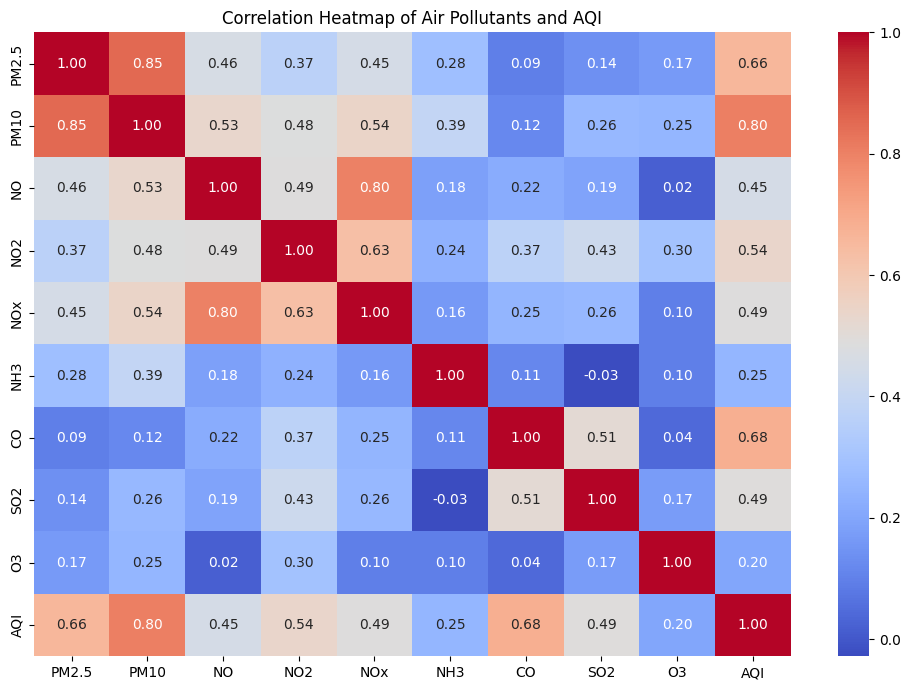

In [34]:
# Calculate correlation matrix
corr_matrix = df_clean[
    ["PM2.5", "PM10", "NO", "NO2", "NOx",
     "NH3", "CO", "SO2", "O3", "AQI"]
].corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Air Pollutants and AQI")
plt.tight_layout()
plt.show()